# UFC Predictor — Hyperparameter Optimization

This notebook tunes Random Forest and CatBoost with Optuna and calibrates the selected model. Mean temporal log loss is the primary metric because probability quality is more important than accuracy alone.

Three expanding-window validation folds are used, while fights from 2024 onward remain held out from model selection.


## 0. Dependencies

Import the optimization, modeling, and evaluation libraries used throughout the notebook.


In [1]:
from pathlib import Path
import gc
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    roc_auc_score,
    log_loss,
    brier_score_loss,
)
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
RANDOM_STATE = 42

print("Optuna:", optuna.__version__)

Optuna: 4.9.0


## 1. Load the Dataset

Locate the project, load the processed fight dataset, and reuse the feature manifest generated by the data pipeline.


In [2]:
def find_project_root(start=None):
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "processed" / "ufcstats" / "fight_dataset.parquet").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find fight_dataset.parquet. Open Jupyter from UFC_PREDICTOR "
        "or set PROJECT_ROOT manually."
    )

PROJECT_ROOT = find_project_root()
DATASET_PATH = PROJECT_ROOT / "data" / "processed" / "ufcstats" / "fight_dataset.parquet"
REPORT_PATH = PROJECT_ROOT / "data" / "processed" / "ufcstats" / "fight_dataset_report.json"
OUTPUT_DIR = PROJECT_ROOT / "models" / "hyperparameter_tuning"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATASET_PATH:", DATASET_PATH)
print("OUTPUT_DIR:", OUTPUT_DIR)

PROJECT_ROOT: C:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR
DATASET_PATH: C:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\data\processed\ufcstats\fight_dataset.parquet
OUTPUT_DIR: C:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\models\hyperparameter_tuning


In [3]:
df = pd.read_parquet(DATASET_PATH).copy()
df["event_date"] = pd.to_datetime(df["event_date"])
df = df.sort_values(["event_date", "fight_order"], kind="stable").reset_index(drop=True)

with open(REPORT_PATH, "r", encoding="utf-8") as f:
    report = json.load(f)

manifest = report["feature_manifest"]
numeric_cols = manifest["numeric_model_features"]
categorical_cols = manifest["categorical_model_features"]
target_col = manifest["target_column"][0]
feature_cols = numeric_cols + categorical_cols

required = feature_cols + [target_col, "event_date"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Expected columns are missing: {missing}")

print("Rows:", len(df))
print("Numerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Target:", target_col)
print("Range:", df["event_date"].min().date(), "→", df["event_date"].max().date())
print("Target=1 rate:", round(float(df[target_col].mean()), 4))

Rows: 8628
Numerical features: 111
Categorical features: 5
Target: target
Range: 1994-03-11 → 2026-07-18
Target=1 rate: 0.5006


## 2. Development and Test Split

Reserve all fights from 2024 onward as the final test set so they cannot influence optimization or calibration.


In [4]:
TEST_START = pd.Timestamp("2024-01-01")

development_df = df[df["event_date"] < TEST_START].copy()
test_df = df[df["event_date"] >= TEST_START].copy()

print(
    "DEVELOPMENT:", len(development_df),
    development_df["event_date"].min().date(), "→", development_df["event_date"].max().date()
)
print(
    "FINAL TEST (held out):", len(test_df),
    test_df["event_date"].min().date(), "→", test_df["event_date"].max().date()
)

assert development_df["event_date"].max() < TEST_START
assert test_df["event_date"].min() >= TEST_START

DEVELOPMENT: 7317 1994-03-11 → 2023-12-16
FINAL TEST (held out): 1311 2024-01-13 → 2026-07-18


## 3. Temporal Validation Folds

Use expanding training windows to preserve chronological order and measure performance across different periods.


In [5]:
FOLD_SPECS = [
    {"name": "fold_1", "val_start": pd.Timestamp("2018-01-01"), "val_end": pd.Timestamp("2020-01-01")},
    {"name": "fold_2", "val_start": pd.Timestamp("2020-01-01"), "val_end": pd.Timestamp("2022-01-01")},
    {"name": "fold_3", "val_start": pd.Timestamp("2022-01-01"), "val_end": pd.Timestamp("2024-01-01")},
]

def get_temporal_fold(data, spec):
    train = data[data["event_date"] < spec["val_start"]].copy()
    val = data[(data["event_date"] >= spec["val_start"]) & (data["event_date"] < spec["val_end"])].copy()
    if train.empty or val.empty:
        raise ValueError(f"{spec['name']} produces an empty training or validation set")
    if train["event_date"].max() >= val["event_date"].min():
        raise AssertionError(f"Temporal leakage detected in {spec['name']}")
    return train, val

fold_summary = []
for spec in FOLD_SPECS:
    tr, va = get_temporal_fold(development_df, spec)
    fold_summary.append({
        "fold": spec["name"],
        "train_rows": len(tr),
        "train_start": tr["event_date"].min().date(),
        "train_end": tr["event_date"].max().date(),
        "val_rows": len(va),
        "val_start": va["event_date"].min().date(),
        "val_end": va["event_date"].max().date(),
        "train_target_mean": float(tr[target_col].mean()),
        "val_target_mean": float(va[target_col].mean()),
    })

pd.DataFrame(fold_summary)

,fold,train_rows,train_start,train_end,val_rows,val_start,val_end,train_target_mean,val_target_mean
0,fold_1,4391,1994-03-11,2017-12-30,975,2018-01-14,2019-12-21,0.507629,0.504615
1,fold_2,5366,1994-03-11,2019-12-21,941,2020-01-18,2021-12-18,0.507082,0.514346
2,fold_3,6307,1994-03-11,2021-12-18,1010,2022-01-15,2023-12-16,0.508166,0.481188


## 4. Preprocessing and Metrics

Random Forest uses median imputation and one-hot encoding; CatBoost retains native categorical features. Both models are evaluated with the same probability metrics.


In [6]:
def prepare_X(frame):
    X = frame[feature_cols].copy()
    for col in numeric_cols:
        X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)
    for col in categorical_cols:
        X[col] = X[col].astype("string").fillna("__MISSING__").astype(str)
    return X


def make_rf_preprocessor():
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median"))])
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", num_pipe, numeric_cols),
        ("cat", cat_pipe, categorical_cols),
    ])


def probability_metrics(y_true, probabilities, threshold=0.5):
    p = np.clip(np.asarray(probabilities, dtype=float), 1e-7, 1 - 1e-7)
    pred = (p >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, p),
        "log_loss": log_loss(y_true, p, labels=[0, 1]),
        "brier_score": brier_score_loss(y_true, p),
    }

## 5. Random Forest Optimization

Minimize mean log loss across the three temporal folds.


In [7]:
def objective_random_forest(trial):
    bootstrap = trial.suggest_categorical("bootstrap", [True, False])
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 1000, step=100),
        "criterion": trial.suggest_categorical("criterion", ["gini", "entropy", "log_loss"]),
        "max_depth": trial.suggest_categorical("max_depth", [None, 6, 8, 10, 12, 16, 20]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 15),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2", 0.5, 0.75, 1.0]),
        "bootstrap": bootstrap,
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }
    if bootstrap:
        params["max_samples"] = trial.suggest_float("max_samples", 0.60, 1.00)

    losses = []
    for i, spec in enumerate(FOLD_SPECS):
        tr, va = get_temporal_fold(development_df, spec)
        X_tr, y_tr = prepare_X(tr), tr[target_col].astype(int).to_numpy()
        X_va, y_va = prepare_X(va), va[target_col].astype(int).to_numpy()

        model = Pipeline([
            ("preprocessor", make_rf_preprocessor()),
            ("classifier", RandomForestClassifier(**params)),
        ])
        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        losses.append(log_loss(y_va, np.clip(p, 1e-7, 1-1e-7), labels=[0, 1]))

        trial.report(float(np.mean(losses)), step=i)
        del model, X_tr, X_va
        gc.collect()
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("fold_log_losses", [float(x) for x in losses])
    return float(np.mean(losses))

In [8]:
N_TRIALS_RF = 30

rf_study = optuna.create_study(
    study_name="ufc_random_forest_temporal_cv",
    direction="minimize",
    sampler=TPESampler(seed=RANDOM_STATE),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1),
)
rf_study.optimize(objective_random_forest, n_trials=N_TRIALS_RF, show_progress_bar=True)

print("Best mean RF log loss:", rf_study.best_value)
rf_study.best_params

  0%|          | 0/30 [00:00<?, ?it/s]

Best mean RF log loss: 0.6614148756952493


{'bootstrap': True,
 'n_estimators': 800,
 'criterion': 'entropy',
 'max_depth': 10,
 'min_samples_split': 16,
 'min_samples_leaf': 10,
 'max_features': 0.5,
 'max_samples': 0.6010348683123408}

## 6. CatBoost Optimization

Tune tree complexity, learning rate, regularization, and sampling parameters using the same folds.


In [9]:
def objective_catboost(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 300, 1200, step=100),
        "depth": trial.suggest_int("depth", 4, 9),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.1, 30.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 5.0, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 5.0),
        "border_count": trial.suggest_categorical("border_count", [64, 128, 254]),
        "loss_function": "Logloss",
        "eval_metric": "Logloss",
        "random_seed": RANDOM_STATE,
        "verbose": False,
        "allow_writing_files": False,
        "thread_count": -1,
    }

    losses = []
    for i, spec in enumerate(FOLD_SPECS):
        tr, va = get_temporal_fold(development_df, spec)
        X_tr, y_tr = prepare_X(tr), tr[target_col].astype(int).to_numpy()
        X_va, y_va = prepare_X(va), va[target_col].astype(int).to_numpy()

        model = CatBoostClassifier(**params)
        model.fit(X_tr, y_tr, cat_features=categorical_cols)
        p = model.predict_proba(X_va)[:, 1]
        losses.append(log_loss(y_va, np.clip(p, 1e-7, 1-1e-7), labels=[0, 1]))

        trial.report(float(np.mean(losses)), step=i)
        del model, X_tr, X_va
        gc.collect()
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("fold_log_losses", [float(x) for x in losses])
    return float(np.mean(losses))

In [10]:
N_TRIALS_CATBOOST = 40

catboost_study = optuna.create_study(
    study_name="ufc_catboost_temporal_cv",
    direction="minimize",
    sampler=TPESampler(seed=RANDOM_STATE),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=1),
)
catboost_study.optimize(objective_catboost, n_trials=N_TRIALS_CATBOOST, show_progress_bar=True)

print("Best mean CatBoost log loss:", catboost_study.best_value)
catboost_study.best_params

  0%|          | 0/40 [00:00<?, ?it/s]

Best mean CatBoost log loss: 0.6630317870792958


{'iterations': 1200,
 'depth': 4,
 'learning_rate': 0.01598972024085743,
 'l2_leaf_reg': 10.990324921335475,
 'random_strength': 4.787285954015766,
 'bagging_temperature': 2.713883374433594,
 'border_count': 64}

## 7. Best Trials

Inspect the strongest trials to verify that the selected solution belongs to a stable parameter region.


In [11]:
def top_trials(study, n=10):
    x = study.trials_dataframe(attrs=("number", "value", "params", "state"))
    return x[x["state"] == "COMPLETE"].sort_values("value").head(n).reset_index(drop=True)

print("Top Random Forest")
display(top_trials(rf_study))
print("Top CatBoost")
display(top_trials(catboost_study))

Top Random Forest


,number,value,params_bootstrap,params_criterion,params_max_depth,params_max_features,params_max_samples,params_min_samples_leaf,params_min_samples_split,params_n_estimators,state
0,15,0.661415,True,entropy,10.0,0.5,0.601035,10,16,800,COMPLETE
1,26,0.661450,True,entropy,10.0,0.5,0.625453,10,16,800,COMPLETE
2,14,0.661648,True,entropy,10.0,1.0,0.604225,9,12,900,COMPLETE
3,21,0.661749,True,entropy,10.0,1.0,0.696031,13,20,900,COMPLETE
4,28,0.661882,True,log_loss,8.0,0.5,0.630068,6,6,600,COMPLETE
5,27,0.662090,True,entropy,10.0,0.5,0.644816,9,15,700,COMPLETE
6,22,0.662183,True,entropy,10.0,1.0,0.653919,12,21,700,COMPLETE
7,2,0.662269,True,entropy,10.0,1.0,0.708540,14,19,1000,COMPLETE
8,23,0.662315,True,entropy,10.0,1.0,0.620261,10,15,900,COMPLETE
9,17,0.662609,True,entropy,8.0,0.5,0.601959,9,11,800,COMPLETE


Top CatBoost


,number,value,params_bagging_temperature,params_border_count,params_depth,params_iterations,params_l2_leaf_reg,params_learning_rate,params_random_strength,state
0,18,0.663032,2.713883,64,4,1200,10.990325,0.015990,4.787286,COMPLETE
1,20,0.663156,1.445393,64,4,1100,9.363990,0.016324,1.946002,COMPLETE
2,21,0.663586,1.641928,64,4,1100,12.606286,0.016001,2.095165,COMPLETE
3,34,0.663854,3.017574,64,5,1000,12.913452,0.011084,1.370630,COMPLETE
4,38,0.664138,1.442075,64,5,700,2.480124,0.013927,0.895875,COMPLETE
5,36,0.664258,1.925215,64,5,900,19.275292,0.012520,0.213950,COMPLETE
6,37,0.664271,4.244668,64,4,1000,4.484791,0.011182,2.055599,COMPLETE
7,31,0.664774,2.448756,64,5,1100,8.864683,0.015505,3.201914,COMPLETE
8,17,0.664826,2.385086,64,5,1100,9.397921,0.015229,4.119830,COMPLETE
9,15,0.665011,2.761138,64,6,400,27.239186,0.025037,4.833224,COMPLETE


## 8. Fold-Level Evaluation

Evaluate the best configuration from each model family on every temporal fold.


In [12]:
def evaluate_best_rf(best_params):
    params = dict(best_params)
    params.update(random_state=RANDOM_STATE, n_jobs=-1)
    if not params.get("bootstrap", True):
        params.pop("max_samples", None)
    rows = []
    for spec in FOLD_SPECS:
        tr, va = get_temporal_fold(development_df, spec)
        X_tr, y_tr = prepare_X(tr), tr[target_col].astype(int).to_numpy()
        X_va, y_va = prepare_X(va), va[target_col].astype(int).to_numpy()
        model = Pipeline([
            ("preprocessor", make_rf_preprocessor()),
            ("classifier", RandomForestClassifier(**params)),
        ])
        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
        m = probability_metrics(y_va, p)
        m.update(model="random_forest", fold=spec["name"], train_rows=len(tr), val_rows=len(va))
        rows.append(m)
        del model, X_tr, X_va
        gc.collect()
    return pd.DataFrame(rows)


def evaluate_best_catboost(best_params):
    params = dict(best_params)
    params.update(
        loss_function="Logloss", eval_metric="Logloss", random_seed=RANDOM_STATE,
        verbose=False, allow_writing_files=False, thread_count=-1,
    )
    rows = []
    for spec in FOLD_SPECS:
        tr, va = get_temporal_fold(development_df, spec)
        X_tr, y_tr = prepare_X(tr), tr[target_col].astype(int).to_numpy()
        X_va, y_va = prepare_X(va), va[target_col].astype(int).to_numpy()
        model = CatBoostClassifier(**params)
        model.fit(X_tr, y_tr, cat_features=categorical_cols)
        p = model.predict_proba(X_va)[:, 1]
        m = probability_metrics(y_va, p)
        m.update(model="catboost", fold=spec["name"], train_rows=len(tr), val_rows=len(va))
        rows.append(m)
        del model, X_tr, X_va
        gc.collect()
    return pd.DataFrame(rows)

rf_best_cv = evaluate_best_rf(rf_study.best_params)
catboost_best_cv = evaluate_best_catboost(catboost_study.best_params)
best_cv_results = pd.concat([rf_best_cv, catboost_best_cv], ignore_index=True)

best_cv_results[[
    "model", "fold", "accuracy", "balanced_accuracy", "roc_auc",
    "log_loss", "brier_score", "train_rows", "val_rows"
]]

,model,fold,accuracy,balanced_accuracy,roc_auc,log_loss,brier_score,train_rows,val_rows
0,random_forest,fold_1,0.598974,0.598912,0.630363,0.665287,0.236479,4391,975
1,random_forest,fold_2,0.599362,0.599246,0.648218,0.660361,0.233939,5366,941
2,random_forest,fold_3,0.600990,0.601805,0.655012,0.658597,0.233120,6307,1010
3,catboost,fold_1,0.590769,0.590630,0.628310,0.666534,0.237155,4391,975
4,catboost,fold_2,0.622742,0.622339,0.650044,0.659853,0.233750,5366,941
5,catboost,fold_3,0.602970,0.603788,0.640947,0.662709,0.235197,6307,1010


## 9. Aggregate Comparison

Compare mean performance and variability across folds to assess temporal stability.


In [7]:
summary = (
    best_cv_results.groupby("model", as_index=False)
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        mean_log_loss=("log_loss", "mean"),
        std_log_loss=("log_loss", "std"),
        mean_brier_score=("brier_score", "mean"),
        std_brier_score=("brier_score", "std"),
    )
    .sort_values("mean_log_loss")
    .reset_index(drop=True)
)
summary

NameError: name 'best_cv_results' is not defined

NameError: name 'best_cv_results' is not defined

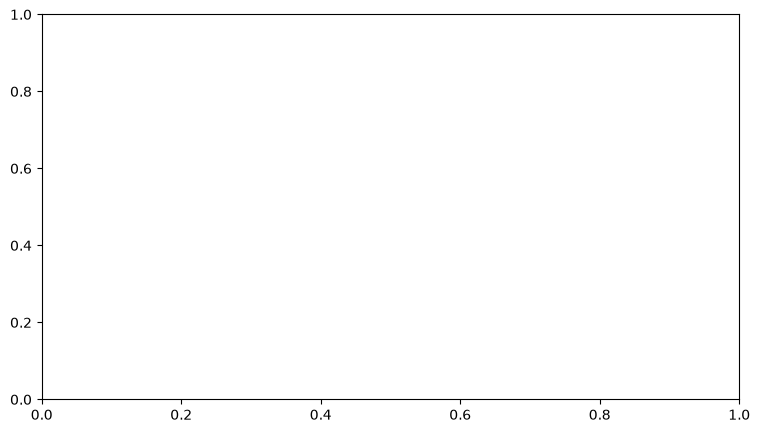

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for model_name, group in best_cv_results.groupby("model"):
    g = group.sort_values("fold")
    ax.plot(g["fold"], g["log_loss"], marker="o", label=model_name)
ax.set_title("Log loss by temporal fold")
ax.set_xlabel("Fold")
ax.set_ylabel("Log loss (lower is better)")
ax.legend()
ax.grid(alpha=0.25)
plt.show()

## 10. Optimization History

Plot trial performance and the best-so-far value to check whether each search has converged.


In [9]:
def plot_study_history(study, title):
    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE and t.value is not None]
    numbers = [t.number for t in completed]
    values = [t.value for t in completed]
    best_so_far = np.minimum.accumulate(values)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.scatter(numbers, values, alpha=0.55, label="Trial")
    ax.plot(numbers, best_so_far, linewidth=2, label="Best so far")
    ax.set_title(title)
    ax.set_xlabel("Trial")
    ax.set_ylabel("Mean temporal log loss")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()

plot_study_history(rf_study, "Random Forest optimization")
plot_study_history(catboost_study, "CatBoost optimization")

NameError: name 'rf_study' is not defined

## 11. Save Initial Results

Store the best parameters, fold-level metrics, summaries, and Optuna trial histories.


In [10]:
payload = {
    "selection_metric": "mean_temporal_log_loss",
    "test_start": str(TEST_START.date()),
    "folds": [
        {
            "name": s["name"],
            "train_rule": f"event_date < {s['val_start'].date()}",
            "validation_rule": f"{s['val_start'].date()} <= event_date < {s['val_end'].date()}",
        }
        for s in FOLD_SPECS
    ],
    "random_forest": {
        "best_mean_log_loss": float(rf_study.best_value),
        "best_params": rf_study.best_params,
    },
    "catboost": {
        "best_mean_log_loss": float(catboost_study.best_value),
        "best_params": catboost_study.best_params,
    },
}

with open(OUTPUT_DIR / "best_hyperparameters.json", "w", encoding="utf-8") as f:
    json.dump(payload, f, indent=2, ensure_ascii=False)

best_cv_results.to_csv(OUTPUT_DIR / "best_models_temporal_cv.csv", index=False)
summary.to_csv(OUTPUT_DIR / "best_models_summary.csv", index=False)
rf_study.trials_dataframe().to_csv(OUTPUT_DIR / "optuna_trials_random_forest.csv", index=False)
catboost_study.trials_dataframe().to_csv(OUTPUT_DIR / "optuna_trials_catboost.csv", index=False)

print("Saved to:", OUTPUT_DIR)

NameError: name 'rf_study' is not defined

## Initial Optimization Summary

Random Forest produced the best mean log loss (`0.6614`), ROC-AUC (`0.645`), and Brier score (`0.2345`). CatBoost achieved slightly higher accuracy but was less stable across time, so Random Forest was retained as the leading model.


## 12. Baseline Check and Focused Refinement

Compare the optimized models against their original baselines, then run a small local search around the best parameter regions. The 2024+ test set remains excluded.


### 12.1. Recover Baseline Parameters

Extract the original constructor arguments from the modeling modules when possible; otherwise use the corresponding library defaults.


In [11]:
import ast
from pprint import pprint


def _call_name(node):
    if isinstance(node, ast.Name):
        return node.id
    if isinstance(node, ast.Attribute):
        return node.attr
    return None


def extract_literal_constructor_kwargs(py_path, class_name):
    """
    Find ClassName(...) calls and recover only keyword arguments that can
    be evaluated as literals.

    Return a list of candidates containing:
    - path
    - line
    - recovered kwargs
    - whether every kwarg was a literal
    """
    py_path = Path(py_path)
    if not py_path.exists():
        return []

    try:
        source = py_path.read_text(encoding="utf-8")
        tree = ast.parse(source)
    except Exception:
        return []

    candidates = []

    for node in ast.walk(tree):
        if not isinstance(node, ast.Call):
            continue

        if _call_name(node.func) != class_name:
            continue

        kwargs = {}
        complete = True

        for kw in node.keywords:
            if kw.arg is None:
                complete = False
                continue

            try:
                kwargs[kw.arg] = ast.literal_eval(kw.value)
            except Exception:
                complete = False

        candidates.append({
            "path": str(py_path),
            "line": getattr(node, "lineno", None),
            "params": kwargs,
            "complete": complete,
        })

    return candidates


MODEL_SOURCE_CANDIDATES = [
    PROJECT_ROOT / "src" / "modeling" / "train_models.py",
    PROJECT_ROOT / "src" / "modeling" / "ufc_modeling.py",
]


def detect_original_baseline(class_name):
    found = []

    for candidate_path in MODEL_SOURCE_CANDIDATES:
        found.extend(
            extract_literal_constructor_kwargs(candidate_path, class_name)
        )

    if not found:
        return None, None

    # Prefer the most explicit fully literal constructor call.
    found = sorted(
        found,
        key=lambda x: (x["complete"], len(x["params"])),
        reverse=True,
    )

    best = found[0]
    return dict(best["params"]), best


detected_rf_params, detected_rf_info = detect_original_baseline(
    "RandomForestClassifier"
)
detected_cat_params, detected_cat_info = detect_original_baseline(
    "CatBoostClassifier"
)


# Use library defaults when the original baseline cannot be recovered.
if detected_rf_params is None:
    BASELINE_RF_PARAMS = {}
    RF_BASELINE_SOURCE = "sklearn defaults"
else:
    BASELINE_RF_PARAMS = detected_rf_params
    RF_BASELINE_SOURCE = (
        f"{detected_rf_info['path']}:{detected_rf_info['line']}"
    )

if detected_cat_params is None:
    BASELINE_CATBOOST_PARAMS = {}
    CATBOOST_BASELINE_SOURCE = "CatBoost defaults"
else:
    BASELINE_CATBOOST_PARAMS = detected_cat_params
    CATBOOST_BASELINE_SOURCE = (
        f"{detected_cat_info['path']}:{detected_cat_info['line']}"
    )


# Keep control parameters consistent across runs.
BASELINE_RF_PARAMS.pop("random_state", None)
BASELINE_RF_PARAMS.pop("n_jobs", None)

for k in [
    "random_seed",
    "verbose",
    "allow_writing_files",
    "thread_count",
    "eval_metric",
    "loss_function",
]:
    BASELINE_CATBOOST_PARAMS.pop(k, None)

# Remove parameters that require a separate evaluation set.
for k in [
    "early_stopping_rounds",
    "use_best_model",
    "od_type",
    "od_wait",
]:
    BASELINE_CATBOOST_PARAMS.pop(k, None)


print("Baseline Random Forest:", RF_BASELINE_SOURCE)
pprint(BASELINE_RF_PARAMS)

print("\nBaseline CatBoost:", CATBOOST_BASELINE_SOURCE)
pprint(BASELINE_CATBOOST_PARAMS)


Baseline Random Forest: C:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\src\modeling\ufc_modeling.py:364
{'class_weight': None}

Baseline CatBoost: C:\Users\pablo\Desktop\PABLO\PROGRAMACION\UFC_PREDICTOR\src\modeling\ufc_modeling.py:399
{}


### 12.2. Evaluation Functions

Use one evaluation procedure for baseline, Stage 1, and refined configurations to keep comparisons consistent.


In [12]:
def evaluate_rf_configuration(params, label):
    params = dict(params)

    params.update(
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    if not params.get("bootstrap", True):
        params.pop("max_samples", None)

    rows = []

    for spec in FOLD_SPECS:
        tr, va = get_temporal_fold(development_df, spec)

        assert tr["event_date"].max() < TEST_START
        assert va["event_date"].max() < TEST_START

        X_tr = prepare_X(tr)
        y_tr = tr[target_col].astype(int).to_numpy()

        X_va = prepare_X(va)
        y_va = va[target_col].astype(int).to_numpy()

        model = Pipeline([
            ("preprocessor", make_rf_preprocessor()),
            ("classifier", RandomForestClassifier(**params)),
        ])

        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]

        metrics = probability_metrics(y_va, p)
        metrics.update(
            candidate=label,
            model_family="random_forest",
            fold=spec["name"],
            train_rows=len(tr),
            val_rows=len(va),
        )
        rows.append(metrics)

        del model, X_tr, X_va
        gc.collect()

    return pd.DataFrame(rows)


def evaluate_catboost_configuration(params, label):
    params = dict(params)

    params.update(
        loss_function="Logloss",
        eval_metric="Logloss",
        random_seed=RANDOM_STATE,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1,
    )

    rows = []

    for spec in FOLD_SPECS:
        tr, va = get_temporal_fold(development_df, spec)

        assert tr["event_date"].max() < TEST_START
        assert va["event_date"].max() < TEST_START

        X_tr = prepare_X(tr)
        y_tr = tr[target_col].astype(int).to_numpy()

        X_va = prepare_X(va)
        y_va = va[target_col].astype(int).to_numpy()

        model = CatBoostClassifier(**params)
        model.fit(
            X_tr,
            y_tr,
            cat_features=categorical_cols,
        )

        p = model.predict_proba(X_va)[:, 1]

        metrics = probability_metrics(y_va, p)
        metrics.update(
            candidate=label,
            model_family="catboost",
            fold=spec["name"],
            train_rows=len(tr),
            val_rows=len(va),
        )
        rows.append(metrics)

        del model, X_tr, X_va
        gc.collect()

    return pd.DataFrame(rows)


def summarize_candidates(results):
    return (
        results
        .groupby(["candidate", "model_family"], as_index=False)
        .agg(
            mean_accuracy=("accuracy", "mean"),
            std_accuracy=("accuracy", "std"),
            mean_balanced_accuracy=("balanced_accuracy", "mean"),
            mean_roc_auc=("roc_auc", "mean"),
            std_roc_auc=("roc_auc", "std"),
            mean_log_loss=("log_loss", "mean"),
            std_log_loss=("log_loss", "std"),
            mean_brier_score=("brier_score", "mean"),
            std_brier_score=("brier_score", "std"),
        )
        .sort_values("mean_log_loss")
        .reset_index(drop=True)
    )


### 12.3. Baseline Comparison

Measure the gain produced by the first Optuna search on the same folds and metrics.


In [13]:
rf_baseline_cv = evaluate_rf_configuration(
    BASELINE_RF_PARAMS,
    "rf_baseline",
)

cat_baseline_cv = evaluate_catboost_configuration(
    BASELINE_CATBOOST_PARAMS,
    "catboost_baseline",
)

rf_stage1_cv = evaluate_rf_configuration(
    rf_study.best_params,
    "rf_optuna_stage1",
)

cat_stage1_cv = evaluate_catboost_configuration(
    catboost_study.best_params,
    "catboost_optuna_stage1",
)

baseline_vs_optimized_results = pd.concat(
    [
        rf_baseline_cv,
        rf_stage1_cv,
        cat_baseline_cv,
        cat_stage1_cv,
    ],
    ignore_index=True,
)

baseline_vs_optimized_summary = summarize_candidates(
    baseline_vs_optimized_results
)

baseline_vs_optimized_summary


NameError: name 'rf_study' is not defined

In [ ]:
def optimization_gain_table(summary_df):
    rows = []

    pairs = [
        ("random_forest", "rf_baseline", "rf_optuna_stage1"),
        ("catboost", "catboost_baseline", "catboost_optuna_stage1"),
    ]

    for family, baseline_name, optimized_name in pairs:
        base = summary_df[
            summary_df["candidate"] == baseline_name
        ].iloc[0]

        opt = summary_df[
            summary_df["candidate"] == optimized_name
        ].iloc[0]

        rows.append({
            "model_family": family,
            "baseline_log_loss": base["mean_log_loss"],
            "optimized_log_loss": opt["mean_log_loss"],
            "log_loss_improvement": (
                base["mean_log_loss"] - opt["mean_log_loss"]
            ),
            "baseline_roc_auc": base["mean_roc_auc"],
            "optimized_roc_auc": opt["mean_roc_auc"],
            "roc_auc_change": (
                opt["mean_roc_auc"] - base["mean_roc_auc"]
            ),
            "baseline_brier": base["mean_brier_score"],
            "optimized_brier": opt["mean_brier_score"],
            "brier_improvement": (
                base["mean_brier_score"] - opt["mean_brier_score"]
            ),
            "baseline_accuracy": base["mean_accuracy"],
            "optimized_accuracy": opt["mean_accuracy"],
            "accuracy_change": (
                opt["mean_accuracy"] - base["mean_accuracy"]
            ),
        })

    return pd.DataFrame(rows)


optimization_gain = optimization_gain_table(
    baseline_vs_optimized_summary
)

optimization_gain


,model_family,baseline_log_loss,optimized_log_loss,log_loss_improvement,baseline_roc_auc,optimized_roc_auc,roc_auc_change,baseline_brier,optimized_brier,brier_improvement,baseline_accuracy,optimized_accuracy,accuracy_change
0,random_forest,0.670423,0.661415,0.009008,0.622026,0.644531,0.022505,0.238787,0.234512,0.004274,0.586134,0.599776,0.013642
1,catboost,0.671759,0.663032,0.008727,0.626450,0.639767,0.013317,0.239339,0.235367,0.003972,0.591564,0.605494,0.013930


### 12.4. Random Forest Refinement

Search locally around the regularized region identified in Stage 1 instead of repeating the full search.


In [ ]:
def objective_random_forest_refined(trial):
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 600, 1200, step=100
        ),
        "criterion": trial.suggest_categorical(
            "criterion", ["entropy", "log_loss"]
        ),
        "max_depth": trial.suggest_int(
            "max_depth", 8, 12
        ),
        "min_samples_split": trial.suggest_int(
            "min_samples_split", 10, 22
        ),
        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf", 7, 15
        ),
        "max_features": trial.suggest_float(
            "max_features", 0.40, 0.80
        ),
        "bootstrap": True,
        "max_samples": trial.suggest_float(
            "max_samples", 0.45, 0.75
        ),
        "random_state": RANDOM_STATE,
        "n_jobs": -1,
    }

    losses = []

    for i, spec in enumerate(FOLD_SPECS):
        tr, va = get_temporal_fold(development_df, spec)

        X_tr = prepare_X(tr)
        y_tr = tr[target_col].astype(int).to_numpy()

        X_va = prepare_X(va)
        y_va = va[target_col].astype(int).to_numpy()

        model = Pipeline([
            ("preprocessor", make_rf_preprocessor()),
            ("classifier", RandomForestClassifier(**params)),
        ])

        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]

        fold_loss = log_loss(
            y_va,
            np.clip(p, 1e-7, 1 - 1e-7),
            labels=[0, 1],
        )
        losses.append(fold_loss)

        trial.report(float(np.mean(losses)), step=i)

        del model, X_tr, X_va
        gc.collect()

        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr(
        "fold_log_losses",
        [float(x) for x in losses],
    )

    return float(np.mean(losses))


N_TRIALS_RF_REFINED = 25

rf_refined_study = optuna.create_study(
    study_name="ufc_random_forest_refined_temporal_cv",
    direction="minimize",
    sampler=TPESampler(seed=RANDOM_STATE + 101),
    pruner=MedianPruner(
        n_startup_trials=8,
        n_warmup_steps=1,
    ),
)

rf_refined_study.optimize(
    objective_random_forest_refined,
    n_trials=N_TRIALS_RF_REFINED,
    show_progress_bar=True,
)

print(
    "Stage 1 RF:",
    rf_study.best_value,
)

print(
    "RF refinement:",
    rf_refined_study.best_value,
)

print(
    "Improvement:",
    rf_study.best_value - rf_refined_study.best_value,
)

rf_refined_study.best_params


  0%|          | 0/25 [00:00<?, ?it/s]

Stage 1 RF: 0.6614148756952493
RF refinement: 0.6609064314293879
Improvement: 0.0005084442658613852


{'n_estimators': 1200,
 'criterion': 'log_loss',
 'max_depth': 11,
 'min_samples_split': 19,
 'min_samples_leaf': 12,
 'max_features': 0.5510343346195377,
 'max_samples': 0.5579613069492467}

### 12.5. CatBoost Refinement

Extend only the Stage 1 boundaries reached by the best CatBoost trials.


In [ ]:
def objective_catboost_refined(trial):
    params = {
        "iterations": trial.suggest_int(
            "iterations", 900, 1800, step=100
        ),
        "depth": trial.suggest_int(
            "depth", 3, 5
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.008, 0.04, log=True
        ),
        "l2_leaf_reg": trial.suggest_float(
            "l2_leaf_reg", 5.0, 25.0, log=True
        ),
        "random_strength": trial.suggest_float(
            "random_strength", 2.0, 10.0, log=True
        ),
        "bagging_temperature": trial.suggest_float(
            "bagging_temperature", 1.0, 5.0
        ),
        "border_count": trial.suggest_categorical(
            "border_count", [32, 64, 96, 128]
        ),
        "loss_function": "Logloss",
        "eval_metric": "Logloss",
        "random_seed": RANDOM_STATE,
        "verbose": False,
        "allow_writing_files": False,
        "thread_count": -1,
    }

    losses = []

    for i, spec in enumerate(FOLD_SPECS):
        tr, va = get_temporal_fold(development_df, spec)

        X_tr = prepare_X(tr)
        y_tr = tr[target_col].astype(int).to_numpy()

        X_va = prepare_X(va)
        y_va = va[target_col].astype(int).to_numpy()

        model = CatBoostClassifier(**params)
        model.fit(
            X_tr,
            y_tr,
            cat_features=categorical_cols,
        )

        p = model.predict_proba(X_va)[:, 1]

        fold_loss = log_loss(
            y_va,
            np.clip(p, 1e-7, 1 - 1e-7),
            labels=[0, 1],
        )
        losses.append(fold_loss)

        trial.report(float(np.mean(losses)), step=i)

        del model, X_tr, X_va
        gc.collect()

        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr(
        "fold_log_losses",
        [float(x) for x in losses],
    )

    return float(np.mean(losses))


N_TRIALS_CATBOOST_REFINED = 25

catboost_refined_study = optuna.create_study(
    study_name="ufc_catboost_refined_temporal_cv",
    direction="minimize",
    sampler=TPESampler(seed=RANDOM_STATE + 202),
    pruner=MedianPruner(
        n_startup_trials=8,
        n_warmup_steps=1,
    ),
)

catboost_refined_study.optimize(
    objective_catboost_refined,
    n_trials=N_TRIALS_CATBOOST_REFINED,
    show_progress_bar=True,
)

print(
    "Stage 1 CatBoost:",
    catboost_study.best_value,
)

print(
    "CatBoost refinement:",
    catboost_refined_study.best_value,
)

print(
    "Improvement:",
    catboost_study.best_value - catboost_refined_study.best_value,
)

catboost_refined_study.best_params


  0%|          | 0/25 [00:00<?, ?it/s]

Stage 1 CatBoost: 0.6630317870792958
CatBoost refinement: 0.6625394974477562
Improvement: 0.0004922896315395775


{'iterations': 1000,
 'depth': 5,
 'learning_rate': 0.014138266100437615,
 'l2_leaf_reg': 6.039819604132925,
 'random_strength': 4.609289632412166,
 'bagging_temperature': 3.9523836511365977,
 'border_count': 64}

### 12.6. Refinement Comparison

Compare Stage 1 and refined configurations using log loss, Brier score, ROC-AUC, accuracy, and fold stability.


In [ ]:
rf_refined_cv = evaluate_rf_configuration(
    rf_refined_study.best_params,
    "rf_refined",
)

cat_refined_cv = evaluate_catboost_configuration(
    catboost_refined_study.best_params,
    "catboost_refined",
)

all_pretest_results = pd.concat(
    [
        rf_baseline_cv,
        rf_stage1_cv,
        rf_refined_cv,
        cat_baseline_cv,
        cat_stage1_cv,
        cat_refined_cv,
    ],
    ignore_index=True,
)

all_pretest_summary = summarize_candidates(
    all_pretest_results
)

all_pretest_summary


,candidate,model_family,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_roc_auc,std_roc_auc,mean_log_loss,std_log_loss,mean_brier_score,std_brier_score
0,rf_refined,random_forest,0.603869,0.003535,0.604133,0.645386,0.013316,0.660906,0.003998,0.234268,0.002004
1,rf_optuna_stage1,random_forest,0.599776,0.001070,0.599987,0.644531,0.012731,0.661415,0.003467,0.234512,0.001752
2,catboost_refined,catboost,0.604431,0.014448,0.604568,0.640184,0.011724,0.662539,0.002765,0.235139,0.001451
3,catboost_optuna_stage1,catboost,0.605494,0.016135,0.605586,0.639767,0.010915,0.663032,0.003352,0.235367,0.001709
4,rf_baseline,random_forest,0.586134,0.014648,0.586278,0.622026,0.013812,0.670423,0.006747,0.238787,0.003048
5,catboost_baseline,catboost,0.591564,0.013718,0.591823,0.626450,0.011001,0.671759,0.005966,0.239339,0.002742


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))

for candidate, group in all_pretest_results.groupby("candidate"):
    g = group.sort_values("fold")
    ax.plot(
        g["fold"],
        g["log_loss"],
        marker="o",
        label=candidate,
    )

ax.set_title("Baseline, Stage 1, and refinement — temporal log loss")
ax.set_xlabel("Fold")
ax.set_ylabel("Log loss (lower is better)")
ax.legend()
ax.grid(alpha=0.25)

plt.show()


### 12.7. Refinement Rule

Accept a refined configuration only when it improves mean log loss by at least `0.0005`. This threshold limits changes driven by negligible variation on the same validation folds.


In [ ]:
MIN_REFINEMENT_GAIN = 0.0005


def choose_stage1_or_refined(
    stage1_params,
    stage1_loss,
    refined_params,
    refined_loss,
    model_name,
):
    gain = float(stage1_loss - refined_loss)

    if gain >= MIN_REFINEMENT_GAIN:
        chosen_stage = "refined"
        chosen_params = dict(refined_params)
        chosen_loss = float(refined_loss)
    else:
        chosen_stage = "stage1"
        chosen_params = dict(stage1_params)
        chosen_loss = float(stage1_loss)

    return {
        "model": model_name,
        "chosen_stage": chosen_stage,
        "mean_log_loss": chosen_loss,
        "refinement_gain": gain,
        "params": chosen_params,
    }


rf_decision = choose_stage1_or_refined(
    rf_study.best_params,
    rf_study.best_value,
    rf_refined_study.best_params,
    rf_refined_study.best_value,
    "random_forest",
)

cat_decision = choose_stage1_or_refined(
    catboost_study.best_params,
    catboost_study.best_value,
    catboost_refined_study.best_params,
    catboost_refined_study.best_value,
    "catboost",
)

pretest_decisions = pd.DataFrame([
    {
        "model": rf_decision["model"],
        "chosen_stage": rf_decision["chosen_stage"],
        "mean_log_loss": rf_decision["mean_log_loss"],
        "refinement_gain": rf_decision["refinement_gain"],
    },
    {
        "model": cat_decision["model"],
        "chosen_stage": cat_decision["chosen_stage"],
        "mean_log_loss": cat_decision["mean_log_loss"],
        "refinement_gain": cat_decision["refinement_gain"],
    },
]).sort_values("mean_log_loss").reset_index(drop=True)

pretest_decisions


,model,chosen_stage,mean_log_loss,refinement_gain
0,random_forest,refined,0.660906,0.000508
1,catboost,stage1,0.663032,0.000492


### 12.8. Frozen Candidate Evaluation

Recalculate all metrics for the configurations retained after refinement.


In [ ]:
FINAL_RF_PARAMS = dict(rf_decision["params"])
FINAL_CATBOOST_PARAMS = dict(cat_decision["params"])

final_rf_cv = evaluate_rf_configuration(
    FINAL_RF_PARAMS,
    "random_forest_final_pretest",
)

final_cat_cv = evaluate_catboost_configuration(
    FINAL_CATBOOST_PARAMS,
    "catboost_final_pretest",
)

final_pretest_results = pd.concat(
    [final_rf_cv, final_cat_cv],
    ignore_index=True,
)

final_pretest_summary = summarize_candidates(
    final_pretest_results
)

final_pretest_summary


,candidate,model_family,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_roc_auc,std_roc_auc,mean_log_loss,std_log_loss,mean_brier_score,std_brier_score
0,random_forest_final_pretest,random_forest,0.603869,0.003535,0.604133,0.645386,0.013316,0.660906,0.003998,0.234268,0.002004
1,catboost_final_pretest,catboost,0.605494,0.016135,0.605586,0.639767,0.010915,0.663032,0.003352,0.235367,0.001709


In [ ]:
# Select the model using the metric defined in advance: mean temporal log loss.
winner_row = (
    final_pretest_summary
    .sort_values("mean_log_loss")
    .iloc[0]
)

SELECTED_MODEL_FAMILY = winner_row["model_family"]

if SELECTED_MODEL_FAMILY == "random_forest":
    SELECTED_MODEL_PARAMS = FINAL_RF_PARAMS
else:
    SELECTED_MODEL_PARAMS = FINAL_CATBOOST_PARAMS

print("MODEL SELECTED BEFORE TESTING:")
print(SELECTED_MODEL_FAMILY)

print("\nMean temporal log loss:")
print(float(winner_row["mean_log_loss"]))

print("\nFrozen hyperparameters:")
pprint(SELECTED_MODEL_PARAMS)


MODEL SELECTED BEFORE TESTING:
random_forest

Mean temporal log loss:
0.6609064314293879

Frozen hyperparameters:
{'criterion': 'log_loss',
 'max_depth': 11,
 'max_features': 0.5510343346195377,
 'max_samples': 0.5579613069492467,
 'min_samples_leaf': 12,
 'min_samples_split': 19,
 'n_estimators': 1200}


### 12.9. Save the Pre-Test Decision

Save the baseline comparison, refinement results, selected model family, and frozen hyperparameters.


In [ ]:
pretest_payload = {
    "selection_metric": "mean_temporal_log_loss",
    "test_start": str(TEST_START.date()),
    "test_used_for_selection": False,
    "minimum_refinement_gain": MIN_REFINEMENT_GAIN,

    "baseline_sources": {
        "random_forest": RF_BASELINE_SOURCE,
        "catboost": CATBOOST_BASELINE_SOURCE,
    },

    "stage1": {
        "random_forest": {
            "mean_log_loss": float(rf_study.best_value),
            "params": rf_study.best_params,
        },
        "catboost": {
            "mean_log_loss": float(catboost_study.best_value),
            "params": catboost_study.best_params,
        },
    },

    "refined": {
        "random_forest": {
            "mean_log_loss": float(rf_refined_study.best_value),
            "params": rf_refined_study.best_params,
        },
        "catboost": {
            "mean_log_loss": float(catboost_refined_study.best_value),
            "params": catboost_refined_study.best_params,
        },
    },

    "accepted_configuration": {
        "random_forest": rf_decision,
        "catboost": cat_decision,
    },

    "selected_model_family": SELECTED_MODEL_FAMILY,
    "selected_model_params": SELECTED_MODEL_PARAMS,
}

with open(
    OUTPUT_DIR / "pretest_model_selection.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        pretest_payload,
        f,
        indent=2,
        ensure_ascii=False,
    )

baseline_vs_optimized_results.to_csv(
    OUTPUT_DIR / "baseline_vs_optimized_by_fold.csv",
    index=False,
)

baseline_vs_optimized_summary.to_csv(
    OUTPUT_DIR / "baseline_vs_optimized_summary.csv",
    index=False,
)

optimization_gain.to_csv(
    OUTPUT_DIR / "optimization_gain.csv",
    index=False,
)

all_pretest_results.to_csv(
    OUTPUT_DIR / "all_pretest_candidates_by_fold.csv",
    index=False,
)

all_pretest_summary.to_csv(
    OUTPUT_DIR / "all_pretest_candidates_summary.csv",
    index=False,
)

final_pretest_results.to_csv(
    OUTPUT_DIR / "final_pretest_models_by_fold.csv",
    index=False,
)

final_pretest_summary.to_csv(
    OUTPUT_DIR / "final_pretest_models_summary.csv",
    index=False,
)

rf_refined_study.trials_dataframe().to_csv(
    OUTPUT_DIR / "optuna_trials_random_forest_refined.csv",
    index=False,
)

catboost_refined_study.trials_dataframe().to_csv(
    OUTPUT_DIR / "optuna_trials_catboost_refined.csv",
    index=False,
)

print("Pre-test phase saved to:")
print(OUTPUT_DIR)


Pre-test phase saved to:
C:\Users\pablo\Desktop\PROGRAMACION\UFC_PREDICTOR\models\hyperparameter_tuning


## 13. Probability Calibration

Compare uncalibrated, sigmoid, and isotonic probabilities for the frozen Random Forest. Calibration is selected entirely within the development period.


### 13.1. Configuration

Add Expected Calibration Error (ECE) as a descriptive measure alongside log loss and Brier score.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
import joblib


CALIBRATION_INNER_WINDOWS = 3
CALIBRATION_WINDOW_YEARS = 2
CALIBRATION_ECE_BINS = 10

# Conservative rule fixed before observing the results.
MIN_CALIBRATION_LOGLOSS_GAIN = 0.0005

print("Frozen Random Forest:")
pprint(FINAL_RF_PARAMS)


Frozen Random Forest:
{'criterion': 'log_loss',
 'max_depth': 11,
 'max_features': 0.5510343346195377,
 'max_samples': 0.5579613069492467,
 'min_samples_leaf': 12,
 'min_samples_split': 19,
 'n_estimators': 1200}


### 13.2. Calibration Methods

Sigmoid calibration fits a logistic transformation of the model logits, while isotonic regression learns a non-parametric monotonic mapping.


In [ ]:
def expected_calibration_error(y_true, probabilities, n_bins=10):
    y = np.asarray(y_true, dtype=int)
    p = np.clip(np.asarray(probabilities, dtype=float), 0.0, 1.0)

    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        if i == n_bins - 1:
            mask = (p >= edges[i]) & (p <= edges[i + 1])
        else:
            mask = (p >= edges[i]) & (p < edges[i + 1])

        if not np.any(mask):
            continue

        bin_weight = mask.mean()
        mean_confidence = p[mask].mean()
        observed_frequency = y[mask].mean()

        ece += bin_weight * abs(mean_confidence - observed_frequency)

    return float(ece)


def full_probability_metrics(y_true, probabilities, threshold=0.5):
    metrics = probability_metrics(
        y_true,
        probabilities,
        threshold=threshold,
    )
    metrics["ece"] = expected_calibration_error(
        y_true,
        probabilities,
        n_bins=CALIBRATION_ECE_BINS,
    )
    return metrics


def probability_to_logit(probabilities):
    p = np.clip(
        np.asarray(probabilities, dtype=float),
        1e-6,
        1 - 1e-6,
    )
    return np.log(p / (1.0 - p)).reshape(-1, 1)


def fit_sigmoid_calibrator(probabilities, y_true):
    calibrator = LogisticRegression(
        C=1e6,
        solver="lbfgs",
        max_iter=2000,
        random_state=RANDOM_STATE,
    )
    calibrator.fit(
        probability_to_logit(probabilities),
        np.asarray(y_true, dtype=int),
    )
    return calibrator


def apply_sigmoid_calibrator(calibrator, probabilities):
    return calibrator.predict_proba(
        probability_to_logit(probabilities)
    )[:, 1]


def fit_isotonic_calibrator(probabilities, y_true):
    calibrator = IsotonicRegression(
        y_min=0.0,
        y_max=1.0,
        out_of_bounds="clip",
    )
    calibrator.fit(
        np.asarray(probabilities, dtype=float),
        np.asarray(y_true, dtype=int),
    )
    return calibrator


def apply_isotonic_calibrator(calibrator, probabilities):
    return np.asarray(
        calibrator.predict(
            np.asarray(probabilities, dtype=float)
        ),
        dtype=float,
    )


### 13.3. Internal Calibration Windows

Generate out-of-fold probabilities from three consecutive two-year windows before each outer validation period. This prevents the calibrator from learning from its evaluation predictions.


In [ ]:
def make_inner_calibration_specs(
    outer_val_start,
    n_windows=CALIBRATION_INNER_WINDOWS,
    window_years=CALIBRATION_WINDOW_YEARS,
):
    outer_val_start = pd.Timestamp(outer_val_start)

    specs = []
    total_years = n_windows * window_years
    first_start = outer_val_start - pd.DateOffset(years=total_years)

    for i in range(n_windows):
        val_start = first_start + pd.DateOffset(
            years=i * window_years
        )
        val_end = val_start + pd.DateOffset(
            years=window_years
        )

        specs.append({
            "name": f"inner_{i + 1}",
            "val_start": pd.Timestamp(val_start),
            "val_end": pd.Timestamp(val_end),
        })

    return specs


for outer_spec in FOLD_SPECS:
    print(
        "\n",
        outer_spec["name"],
        "outer validation:",
        outer_spec["val_start"].date(),
        "→",
        outer_spec["val_end"].date(),
    )

    for inner_spec in make_inner_calibration_specs(
        outer_spec["val_start"]
    ):
        print(
            "   ",
            inner_spec["name"],
            inner_spec["val_start"].date(),
            "→",
            inner_spec["val_end"].date(),
        )



 fold_1 outer validation: 2018-01-01 → 2020-01-01
    inner_1 2012-01-01 → 2014-01-01
    inner_2 2014-01-01 → 2016-01-01
    inner_3 2016-01-01 → 2018-01-01

 fold_2 outer validation: 2020-01-01 → 2022-01-01
    inner_1 2014-01-01 → 2016-01-01
    inner_2 2016-01-01 → 2018-01-01
    inner_3 2018-01-01 → 2020-01-01

 fold_3 outer validation: 2022-01-01 → 2024-01-01
    inner_1 2016-01-01 → 2018-01-01
    inner_2 2018-01-01 → 2020-01-01
    inner_3 2020-01-01 → 2022-01-01


### 13.4. Calibration Predictions

Generate temporal out-of-fold probabilities using the frozen Random Forest parameters.


In [ ]:
def frozen_rf_params():
    params = dict(FINAL_RF_PARAMS)
    params.update(
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return params


def fit_frozen_rf(train_frame):
    X_train = prepare_X(train_frame)
    y_train = train_frame[target_col].astype(int).to_numpy()

    model = Pipeline([
        ("preprocessor", make_rf_preprocessor()),
        ("classifier", RandomForestClassifier(
            **frozen_rf_params()
        )),
    ])

    model.fit(X_train, y_train)
    return model


def temporal_calibration_oof(
    outer_train,
    outer_val_start,
):
    """
    Produce temporal OOF predictions within the training data
    of an outer fold.
    """
    prediction_parts = []

    inner_specs = make_inner_calibration_specs(
        outer_val_start
    )

    for inner_spec in inner_specs:
        inner_train = outer_train[
            outer_train["event_date"] < inner_spec["val_start"]
        ].copy()

        inner_val = outer_train[
            (outer_train["event_date"] >= inner_spec["val_start"])
            & (outer_train["event_date"] < inner_spec["val_end"])
        ].copy()

        if inner_train.empty or inner_val.empty:
            raise ValueError(
                f"{inner_spec['name']} does not contain enough data."
            )

        if inner_train["event_date"].max() >= inner_val["event_date"].min():
            raise AssertionError(
                f"Temporal leakage in {inner_spec['name']}."
            )

        model = fit_frozen_rf(inner_train)

        X_inner_val = prepare_X(inner_val)
        p = model.predict_proba(X_inner_val)[:, 1]

        part = pd.DataFrame({
            "event_date": inner_val["event_date"].to_numpy(),
            "y_true": inner_val[target_col].astype(int).to_numpy(),
            "raw_probability": p,
            "inner_fold": inner_spec["name"],
        })

        prediction_parts.append(part)

        del model, X_inner_val
        gc.collect()

    oof = pd.concat(
        prediction_parts,
        ignore_index=True,
    )

    return oof.sort_values("event_date").reset_index(drop=True)


### 13.5. Nested Calibration Evaluation

Fit both calibrators inside each outer fold and compare them with the original probabilities on the outer validation period.


In [ ]:
calibration_rows = []
outer_prediction_parts = []
calibration_training_parts = []

for outer_spec in FOLD_SPECS:
    outer_train, outer_val = get_temporal_fold(
        development_df,
        outer_spec,
    )

    assert outer_val["event_date"].max() < TEST_START

    # Generate OOF predictions for calibration.
    calibration_oof = temporal_calibration_oof(
        outer_train,
        outer_spec["val_start"],
    )

    calibration_oof["outer_fold"] = outer_spec["name"]
    calibration_training_parts.append(calibration_oof)

    sigmoid_calibrator = fit_sigmoid_calibrator(
        calibration_oof["raw_probability"],
        calibration_oof["y_true"],
    )

    isotonic_calibrator = fit_isotonic_calibrator(
        calibration_oof["raw_probability"],
        calibration_oof["y_true"],
    )

    # Fit the model on the complete outer-fold training set.
    outer_model = fit_frozen_rf(outer_train)

    X_outer_val = prepare_X(outer_val)
    y_outer_val = outer_val[target_col].astype(int).to_numpy()

    raw_p = outer_model.predict_proba(
        X_outer_val
    )[:, 1]

    sigmoid_p = apply_sigmoid_calibrator(
        sigmoid_calibrator,
        raw_p,
    )

    isotonic_p = apply_isotonic_calibrator(
        isotonic_calibrator,
        raw_p,
    )

    probabilities_by_method = {
        "uncalibrated": raw_p,
        "sigmoid": sigmoid_p,
        "isotonic": isotonic_p,
    }

    for method, p in probabilities_by_method.items():
        metrics = full_probability_metrics(
            y_outer_val,
            p,
        )

        metrics.update({
            "calibration_method": method,
            "fold": outer_spec["name"],
            "train_rows": len(outer_train),
            "calibration_rows": len(calibration_oof),
            "val_rows": len(outer_val),
        })

        calibration_rows.append(metrics)

        outer_prediction_parts.append(pd.DataFrame({
            "event_date": outer_val["event_date"].to_numpy(),
            "y_true": y_outer_val,
            "probability": p,
            "calibration_method": method,
            "fold": outer_spec["name"],
        }))

    del outer_model, X_outer_val
    gc.collect()


calibration_cv_results = pd.DataFrame(calibration_rows)

calibration_predictions = pd.concat(
    outer_prediction_parts,
    ignore_index=True,
)

calibration_training_oof = pd.concat(
    calibration_training_parts,
    ignore_index=True,
)

calibration_cv_results


,accuracy,balanced_accuracy,roc_auc,log_loss,brier_score,ece,calibration_method,fold,train_rows,calibration_rows,val_rows
0,0.600000,0.600004,0.630262,0.665373,0.236525,0.025736,uncalibrated,fold_1,4391,2596,975
1,0.604103,0.604372,0.630262,0.665212,0.236500,0.045238,sigmoid,fold_1,4391,2596,975
2,0.600000,0.600496,0.626826,0.665446,0.236713,0.028518,isotonic,fold_1,4391,2596,975
3,0.604676,0.604716,0.650546,0.659683,0.233582,0.022995,uncalibrated,fold_2,5366,2862,941
4,0.600425,0.601255,0.650546,0.659401,0.233422,0.025115,sigmoid,fold_2,5366,2862,941
5,0.594049,0.596400,0.647513,0.663634,0.235023,0.032872,isotonic,fold_2,5366,2862,941
6,0.606931,0.607679,0.655350,0.657663,0.232697,0.027041,uncalibrated,fold_3,6307,2845,1010
7,0.616832,0.616699,0.655350,0.655857,0.231863,0.024297,sigmoid,fold_3,6307,2845,1010
8,0.612871,0.609898,0.657745,0.669417,0.231798,0.037397,isotonic,fold_3,6307,2845,1010


### 13.6. Aggregate Calibration Results

Compare mean log loss, Brier score, ECE, and stability across folds.


In [ ]:
calibration_summary = (
    calibration_cv_results
    .groupby("calibration_method", as_index=False)
    .agg(
        mean_accuracy=("accuracy", "mean"),
        std_accuracy=("accuracy", "std"),
        mean_balanced_accuracy=("balanced_accuracy", "mean"),
        mean_roc_auc=("roc_auc", "mean"),
        std_roc_auc=("roc_auc", "std"),
        mean_log_loss=("log_loss", "mean"),
        std_log_loss=("log_loss", "std"),
        mean_brier_score=("brier_score", "mean"),
        std_brier_score=("brier_score", "std"),
        mean_ece=("ece", "mean"),
        std_ece=("ece", "std"),
    )
    .sort_values(
        ["mean_log_loss", "mean_brier_score"]
    )
    .reset_index(drop=True)
)

calibration_summary


,calibration_method,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_roc_auc,std_roc_auc,mean_log_loss,std_log_loss,mean_brier_score,std_brier_score,mean_ece,std_ece
0,sigmoid,0.607120,0.008609,0.607442,0.645386,0.013316,0.660157,0.004723,0.233928,0.002360,0.031550,0.011861
1,uncalibrated,0.603869,0.003535,0.604133,0.645386,0.013316,0.660906,0.003998,0.234268,0.002004,0.025257,0.002065
2,isotonic,0.602307,0.009621,0.602265,0.644028,0.015751,0.666166,0.002958,0.234511,0.002497,0.032929,0.004440


### 13.7. Calibration Gain

Measure each calibration method against the uncalibrated Random Forest.


In [ ]:
raw_row = calibration_summary[
    calibration_summary["calibration_method"] == "uncalibrated"
].iloc[0]

calibration_gain_rows = []

for _, row in calibration_summary.iterrows():
    calibration_gain_rows.append({
        "calibration_method": row["calibration_method"],
        "log_loss_gain_vs_raw": (
            raw_row["mean_log_loss"] - row["mean_log_loss"]
        ),
        "brier_gain_vs_raw": (
            raw_row["mean_brier_score"] - row["mean_brier_score"]
        ),
        "ece_gain_vs_raw": (
            raw_row["mean_ece"] - row["mean_ece"]
        ),
        "roc_auc_change_vs_raw": (
            row["mean_roc_auc"] - raw_row["mean_roc_auc"]
        ),
        "accuracy_change_vs_raw": (
            row["mean_accuracy"] - raw_row["mean_accuracy"]
        ),
    })

calibration_gain = pd.DataFrame(
    calibration_gain_rows
).sort_values(
    "log_loss_gain_vs_raw",
    ascending=False,
).reset_index(drop=True)

calibration_gain


,calibration_method,log_loss_gain_vs_raw,brier_gain_vs_raw,ece_gain_vs_raw,roc_auc_change_vs_raw,accuracy_change_vs_raw
0,sigmoid,0.000750,0.000339,-0.006293,0.000000,0.003251
1,uncalibrated,0.000000,0.000000,0.000000,0.000000,0.000000
2,isotonic,-0.005259,-0.000243,-0.007671,-0.001358,-0.001562


### 13.8. Reliability Diagrams

Compare predicted probabilities with observed win frequencies using quantile bins.


In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration",
)

for method in ["uncalibrated", "sigmoid", "isotonic"]:
    subset = calibration_predictions[
        calibration_predictions["calibration_method"] == method
    ]

    prob_true, prob_pred = calibration_curve(
        subset["y_true"],
        subset["probability"],
        n_bins=10,
        strategy="quantile",
    )

    ax.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=method,
    )

ax.set_title("Reliability diagram — temporal validation")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed win frequency")
ax.legend()
ax.grid(alpha=0.25)

plt.show()


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

for method in ["uncalibrated", "sigmoid", "isotonic"]:
    subset = calibration_predictions[
        calibration_predictions["calibration_method"] == method
    ]

    ax.hist(
        subset["probability"],
        bins=20,
        alpha=0.35,
        label=method,
    )

ax.set_title("Probability distribution")
ax.set_xlabel("P(fighter_a wins)")
ax.set_ylabel("Number of fights")
ax.legend()

plt.show()


### 13.9. Calibration Selection

Accept calibration only when mean log loss improves by at least `0.0005` and mean Brier score does not worsen.


In [ ]:
raw = calibration_summary[
    calibration_summary["calibration_method"] == "uncalibrated"
].iloc[0]

best_candidate = (
    calibration_summary
    .sort_values(
        ["mean_log_loss", "mean_brier_score"]
    )
    .iloc[0]
)

best_method = best_candidate["calibration_method"]

if best_method == "uncalibrated":
    SELECTED_CALIBRATION_METHOD = "uncalibrated"
    CALIBRATION_ACCEPTED = False

else:
    logloss_gain = float(
        raw["mean_log_loss"]
        - best_candidate["mean_log_loss"]
    )

    brier_not_worse = (
        best_candidate["mean_brier_score"]
        <= raw["mean_brier_score"]
    )

    if (
        logloss_gain >= MIN_CALIBRATION_LOGLOSS_GAIN
        and brier_not_worse
    ):
        SELECTED_CALIBRATION_METHOD = best_method
        CALIBRATION_ACCEPTED = True
    else:
        SELECTED_CALIBRATION_METHOD = "uncalibrated"
        CALIBRATION_ACCEPTED = False


print("SELECTED CALIBRATION METHOD:")
print(SELECTED_CALIBRATION_METHOD)

print("\nIs additional calibration accepted?")
print(CALIBRATION_ACCEPTED)

print("\nSummary:")
calibration_summary


SELECTED CALIBRATION METHOD:
sigmoid

Is additional calibration accepted?
True

Summary:


,calibration_method,mean_accuracy,std_accuracy,mean_balanced_accuracy,mean_roc_auc,std_roc_auc,mean_log_loss,std_log_loss,mean_brier_score,std_brier_score,mean_ece,std_ece
0,sigmoid,0.607120,0.008609,0.607442,0.645386,0.013316,0.660157,0.004723,0.233928,0.002360,0.031550,0.011861
1,uncalibrated,0.603869,0.003535,0.604133,0.645386,0.013316,0.660906,0.003998,0.234268,0.002004,0.025257,0.002065
2,isotonic,0.602307,0.009621,0.602265,0.644028,0.015751,0.666166,0.002958,0.234511,0.002497,0.032929,0.004440


### 13.10. Final Calibrator

Fit the selected calibrator on temporal OOF predictions and train the frozen Random Forest on all development data before 2024.


In [ ]:
FINAL_CALIBRATION_SPECS = [
    {
        "name": "cal_2016_2017",
        "val_start": pd.Timestamp("2016-01-01"),
        "val_end": pd.Timestamp("2018-01-01"),
    },
    {
        "name": "cal_2018_2019",
        "val_start": pd.Timestamp("2018-01-01"),
        "val_end": pd.Timestamp("2020-01-01"),
    },
    {
        "name": "cal_2020_2021",
        "val_start": pd.Timestamp("2020-01-01"),
        "val_end": pd.Timestamp("2022-01-01"),
    },
    {
        "name": "cal_2022_2023",
        "val_start": pd.Timestamp("2022-01-01"),
        "val_end": pd.Timestamp("2024-01-01"),
    },
]


def build_final_calibration_oof():
    parts = []

    for spec in FINAL_CALIBRATION_SPECS:
        tr = development_df[
            development_df["event_date"] < spec["val_start"]
        ].copy()

        va = development_df[
            (development_df["event_date"] >= spec["val_start"])
            & (development_df["event_date"] < spec["val_end"])
        ].copy()

        if tr.empty or va.empty:
            raise ValueError(
                f"{spec['name']} produces an empty training or validation set."
            )

        if tr["event_date"].max() >= va["event_date"].min():
            raise AssertionError(
                f"Temporal leakage in {spec['name']}."
            )

        model = fit_frozen_rf(tr)
        X_va = prepare_X(va)

        p = model.predict_proba(X_va)[:, 1]

        parts.append(pd.DataFrame({
            "event_date": va["event_date"].to_numpy(),
            "y_true": va[target_col].astype(int).to_numpy(),
            "raw_probability": p,
            "calibration_window": spec["name"],
        }))

        del model, X_va
        gc.collect()

    return (
        pd.concat(parts, ignore_index=True)
        .sort_values("event_date")
        .reset_index(drop=True)
    )


final_calibration_oof = build_final_calibration_oof()

print("OOF predictions for the final calibrator:", len(final_calibration_oof))
print(
    final_calibration_oof["event_date"].min().date(),
    "→",
    final_calibration_oof["event_date"].max().date(),
)


OOF predictions for the final calibrator: 3855
2016-01-02 → 2023-12-16


In [ ]:
if SELECTED_CALIBRATION_METHOD == "sigmoid":
    FINAL_CALIBRATOR = fit_sigmoid_calibrator(
        final_calibration_oof["raw_probability"],
        final_calibration_oof["y_true"],
    )

elif SELECTED_CALIBRATION_METHOD == "isotonic":
    FINAL_CALIBRATOR = fit_isotonic_calibrator(
        final_calibration_oof["raw_probability"],
        final_calibration_oof["y_true"],
    )

else:
    FINAL_CALIBRATOR = None


# Fit the final model on all development data before 2024.
FINAL_PRETEST_RF_MODEL = fit_frozen_rf(
    development_df
)

print("Final pre-test model trained on:", len(development_df), "fights")
print("Calibration:", SELECTED_CALIBRATION_METHOD)
print("Test used:", False)


Final pre-test model trained on: 7317 fights
Calibration: sigmoid
Test used: False


### 13.11. Save the Frozen Pipeline

Store the final Random Forest, calibrator, selection metadata, and calibration results without evaluating the test set.


In [ ]:
CALIBRATION_OUTPUT_DIR = OUTPUT_DIR / "calibration"
CALIBRATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

joblib.dump(
    FINAL_PRETEST_RF_MODEL,
    CALIBRATION_OUTPUT_DIR / "random_forest_pretest.joblib",
)

if FINAL_CALIBRATOR is not None:
    joblib.dump(
        FINAL_CALIBRATOR,
        CALIBRATION_OUTPUT_DIR / "probability_calibrator.joblib",
    )


calibration_payload = {
    "model_family": "random_forest",
    "model_params": FINAL_RF_PARAMS,
    "selection_metric": "mean_temporal_log_loss",
    "selected_calibration_method": SELECTED_CALIBRATION_METHOD,
    "calibration_accepted": bool(CALIBRATION_ACCEPTED),
    "minimum_log_loss_gain": MIN_CALIBRATION_LOGLOSS_GAIN,
    "test_start": str(TEST_START.date()),
    "test_used": False,
}

with open(
    CALIBRATION_OUTPUT_DIR / "calibration_selection.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        calibration_payload,
        f,
        indent=2,
        ensure_ascii=False,
    )


calibration_cv_results.to_csv(
    CALIBRATION_OUTPUT_DIR / "calibration_cv_by_fold.csv",
    index=False,
)

calibration_summary.to_csv(
    CALIBRATION_OUTPUT_DIR / "calibration_summary.csv",
    index=False,
)

calibration_gain.to_csv(
    CALIBRATION_OUTPUT_DIR / "calibration_gain_vs_raw.csv",
    index=False,
)

calibration_predictions.to_csv(
    CALIBRATION_OUTPUT_DIR / "calibration_outer_predictions.csv",
    index=False,
)

final_calibration_oof.to_csv(
    CALIBRATION_OUTPUT_DIR / "final_calibration_oof.csv",
    index=False,
)

print("Results saved to:")
print(CALIBRATION_OUTPUT_DIR)


Results saved to:
C:\Users\pablo\Desktop\PROGRAMACION\UFC_PREDICTOR\models\hyperparameter_tuning\calibration


## Summary

Random Forest was selected after baseline comparison and focused refinement, with a final mean temporal log loss of `0.6609`. Sigmoid calibration was accepted and the complete pre-test pipeline was saved. The 2024+ test set was not used during model or calibration selection.
